# Homework Five (DSC 210, Spring 2026)
Name: Jacob Bauer

Date: 2026-04-08

This dataset ('airline_satisfaction.csv') contains an airline passenger satisfaction survey. The final goal for this homework is to predict passenger satisfaction.

Features:
- Gender: Gender of the passengers (Female, Male)
- Customer Type: The customer type (Loyal customer, disloyal customer)
- Age: The actual age of the passengers
- Type of Travel: Purpose of the flight of the passengers (Personal Travel, Business Travel)
- Class: Travel class in the plane of the passengers (Business, Eco, Eco Plus)
- Flight distance: The flight distance of this journey
- Inflight wifi service: Satisfaction level of the inflight wifi service (0:Not Applicable;1-5)
- Departure/Arrival time convenient: Satisfaction level of Departure/Arrival time convenient
- Ease of Online booking: Satisfaction level of online booking
- Gate location: Satisfaction level of Gate location
- Food and drink: Satisfaction level of Food and drink
- Online boarding: Satisfaction level of online boarding
- Seat comfort: Satisfaction level of Seat comfort
- Inflight entertainment: Satisfaction level of inflight entertainment
- On-board service: Satisfaction level of On-board service
- Leg room service: Satisfaction level of Leg room service
- Baggage handling: Satisfaction level of baggage handling
- Check-in service: Satisfaction level of Check-in service
- Inflight service: Satisfaction level of inflight service
- Cleanliness: Satisfaction level of Cleanliness
- Departure Delay in Minutes: Minutes delayed when departure
- Arrival Delay in Minutes: Minutes delayed when Arrival
- **Satisfaction**: Airline satisfaction level (satisfied vs "neutral or dissatisfied") -- *this is the target/label*

1. Investigate and clean up the dataset. You should consider steps such as:
  - Detecting/handling outliers
  - Detecting/handling missing values
  - Check for highly correlated features
  - Convert categorical variables to numeric (one-hot encoding) when/if appropriate

This list is not exhaustive -- there may be other steps that are appropriate here. The list is also not very specific! Your job is to choose reasonable options for cleaning the data. **You also need to explain/justify your choices.**

id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction                           0
dtype: int64


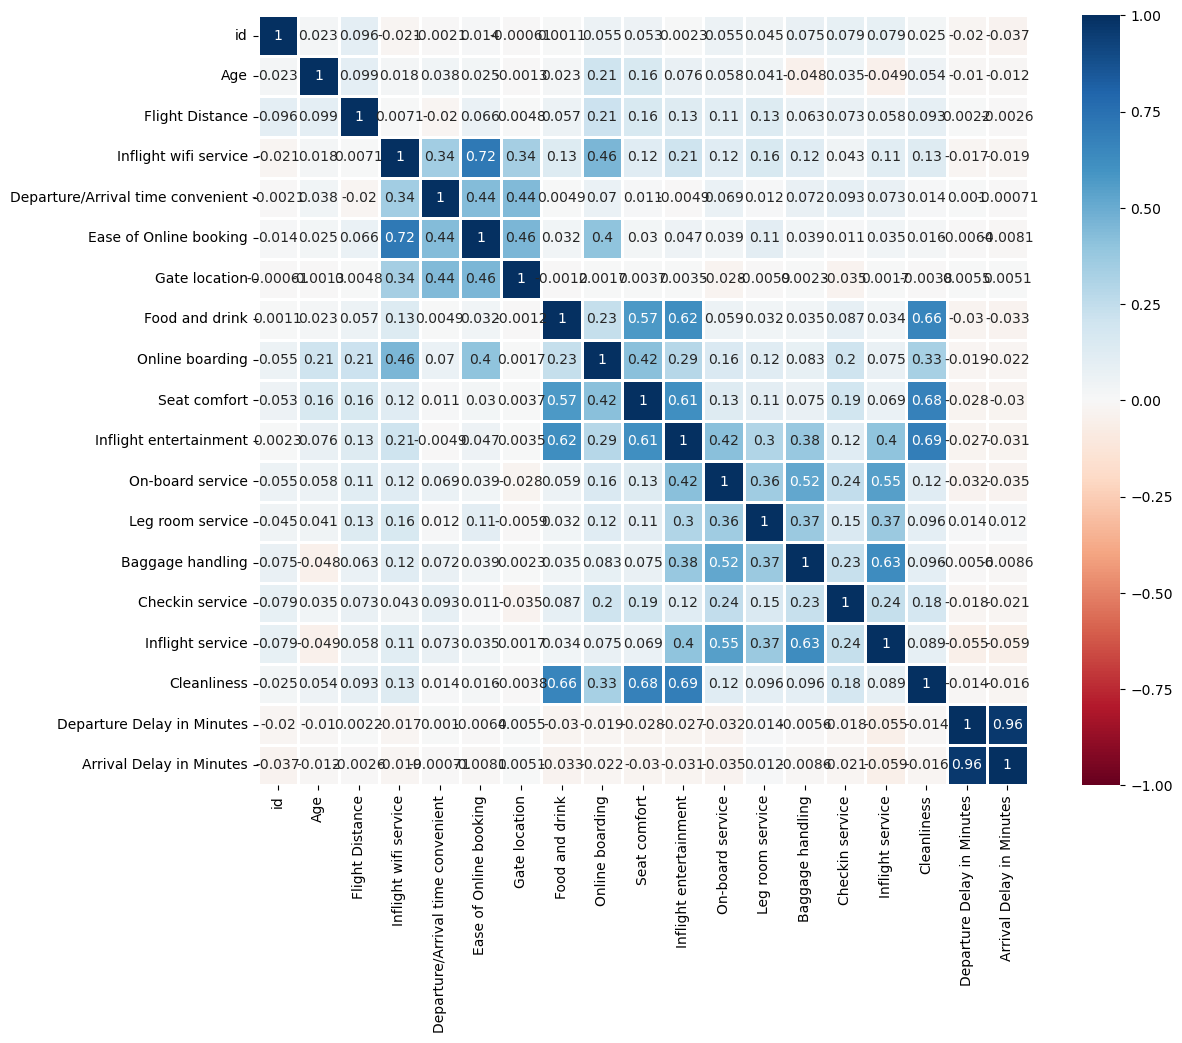

<class 'pandas.core.frame.DataFrame'>
Index: 93513 entries, 0 to 103903
Data columns (total 24 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   id                                 93513 non-null  float64
 1   Age                                93513 non-null  float64
 2   Flight Distance                    93513 non-null  float64
 3   Inflight wifi service              93513 non-null  float64
 4   Departure/Arrival time convenient  93513 non-null  float64
 5   Ease of Online booking             93513 non-null  float64
 6   Gate location                      93513 non-null  float64
 7   Food and drink                     93513 non-null  float64
 8   Online boarding                    93513 non-null  float64
 9   Seat comfort                       93513 non-null  float64
 10  Inflight entertainment             93513 non-null  float64
 11  On-board service                   93513 non-null  float64

In [31]:
from matplotlib import pyplot as plt
import seaborn as sns 
import pandas as pd 
from sklearn.ensemble import IsolationForest
from sklearn.impute import KNNImputer
air_df = pd.read_csv("airline_satisfaction.csv")
print(air_df.isnull().sum())

imputer = KNNImputer(n_neighbors=5)


air_df[air_df.select_dtypes(include=["number"]).columns] = imputer.fit_transform(
    air_df.select_dtypes(include=["number"])
)

                        

iso_forest = IsolationForest(
    n_estimators=100,  
    contamination=0.1, 
    n_jobs=-1, 
    random_state=42, 
    verbose=0)

air_num_df = air_df.copy()
air_num_df = air_num_df.drop(columns = ["Gender", "Customer Type", "Type of Travel", "Class", "satisfaction"])
iso_forest.fit(air_num_df)
outlier_class = iso_forest.predict(air_num_df)
air_df["Outliers"] = outlier_class
air_df_clean = air_df.copy()
air_df_clean = air_df_clean[air_df_clean["Outliers"] == 1]
air_df_clean = air_df_clean.drop(columns = "Outliers") # This was used to drop any outliers, assuming with the size of the data that aroud 10% of the data would contain outliers.


corr_matrix = air_num_df.corr()
plt.figure(figsize=(14, 10)) 
sns.heatmap(
    air_num_df.corr(numeric_only=True),
    vmin=-1, vmax=1,
    square=True, lw=2,
    annot=True, cmap="RdBu",
)
plt.show()
air_df_clean = air_df_clean.drop(columns = "Departure Delay in Minutes") # Found to be highly correlated with another column so it was dropped, doesn't affect customer staisfaction as much as arrival delay in minutes.
cat_cols = ["Gender", "Customer Type", "Type of Travel", "Class", "satisfaction"]
air_df_clean = pd.get_dummies(air_df_clean, columns=cat_cols, drop_first=True)
print(air_df_clean.info())

2. Split the data into training and testing sets, then scale the variables. Explain your choices.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
y = air_df_clean["satisfaction_satisfied"] # This is the variable we are looking to test on
air_df_clean_train, air_df_clean_test, y_train, y_test = train_test_split(air_df_clean,
                                                                          y, 
                                                                          test_size = 0.25, 
                                                                          random_state = 0) # Picked 25% of the data for testing because it si standard
air_df_clean_train = air_df_clean_train.drop(columns = "satisfaction_satisfied", axis = 1)
air_df_clean_test = air_df_clean_test.drop(columns = "satisfaction_satisfied", axis = 1)
print(air_df_clean_train.shape, air_df_clean_test.shape, y_train.shape, y_test.shape)
scaler = StandardScaler().fit(air_df_clean_train)

air_df_clean_train = pd.DataFrame(scaler.transform(air_df_clean_train), columns=air_df_clean_train.columns) # Standardize train data
air_df_clean_test = pd.DataFrame(scaler.transform(air_df_clean_test), columns=air_df_clean_test.columns) # Standardize test data

air_df_clean_train.head()

(70134, 23) (23379, 23) (70134,) (23379,)


,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Inflight service,Cleanliness,Arrival Delay in Minutes,Gender_Male,Customer Type_disloyal Customer,Type of Travel_Personal Travel,Class_Eco,Class_Eco Plus
0,1.331885,-0.500421,-0.781974,0.946192,0.605364,0.882663,0.798589,-1.738644,0.540210,-1.963494,...,0.264709,1.346822,0.249182,-1.840829,-0.461584,-0.990407,2.125256,-0.669777,-0.899976,-0.275061
1,-1.756944,1.043124,-1.092177,0.946192,0.605364,0.882663,0.002678,0.589914,0.540210,0.394232,...,1.160490,1.346822,0.249182,0.524939,-0.461584,1.009686,2.125256,-0.669777,-0.899976,-0.275061
2,-0.222428,0.304907,-0.632995,1.734580,1.283064,1.631661,1.594501,-0.186272,0.540210,1.180140,...,0.264709,-0.263921,0.249182,-0.263650,-0.461584,-0.990407,-0.470531,-0.669777,-0.899976,-0.275061
3,-1.737041,1.110235,-0.419730,-1.418973,-1.427738,-1.364331,-1.589144,-0.186272,0.540210,1.180140,...,1.160490,1.346822,1.157741,1.313529,-0.272555,1.009686,-0.470531,-0.669777,-0.899976,-0.275061
4,-0.748928,0.573350,0.037412,1.734580,1.283064,1.631661,1.594501,-0.962458,-1.783485,-1.177585,...,1.160490,-0.263921,1.157741,0.524939,-0.461584,-0.990407,-0.470531,-0.669777,-0.899976,-0.275061


3. Apply k-nearest-neighbors to classify the overall satisfaction of the passengers who took this survey. You should train your model on the training data, then apply the model to the test data. Create a confusion matrix (or visualization) to show how well the model performed. What was the overall accuracy of this model on test data?

[False  True]
[ True False  True ... False False False]
[[12835   467]
 [ 1128  8949]]
Accuracy: 0.9317763805124257


<Axes: >

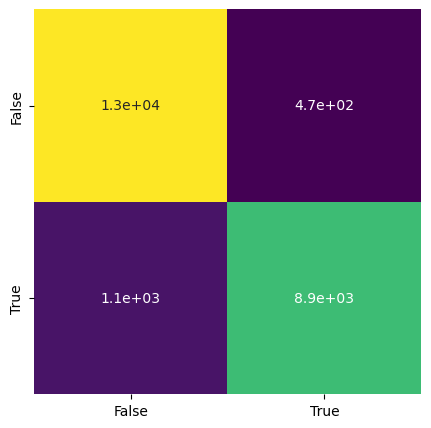

In [33]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(air_df_clean_train, y_train)

print(knn.classes_)
prediction_air = knn.predict(air_df_clean_test)
print(prediction_air)

print(confusion_matrix(y_test, prediction_air))

accuracy_KNN = accuracy_score(y_test, prediction_air) # This is a really cool thing ai showed me to show the accuracy of the model
print("Accuracy:", accuracy_KNN)

fig, ax = plt.subplots(figsize=(5, 5))

sns.heatmap(confusion_matrix(y_test, prediction_air),
           annot=True, cmap="viridis", cbar=False,
           xticklabels=knn.classes_,
           yticklabels=knn.classes_)

4. Apply logistic regression to classify the overall satisfaction of the passengers who took this survey. You should train your model on the training data, then apply the model to the test data. Create a confusion matrix (or visualization) to show how well the model performed. What was the overall accuracy of this model on test data?

Accuracy: 0.8880619359254032


<Axes: >

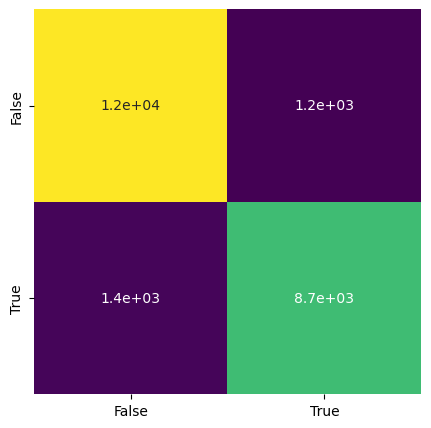

In [34]:
from sklearn.linear_model import LogisticRegression
import numpy as np


log_reg = LogisticRegression()
log_reg.fit(air_df_clean_train, y_train)

y_predict = log_reg.predict(air_df_clean_test)

accuracy_LOG = accuracy_score(y_test, y_predict) # This is a really cool thing ai showed me to show the accuracy of the model
print("Accuracy:", accuracy_LOG)

fig, ax = plt.subplots(figsize=(5, 5))

sns.heatmap(confusion_matrix(y_test, y_predict),
           annot=True, cmap="viridis", cbar=False,
           xticklabels=knn.classes_,
           yticklabels=knn.classes_)



5. Which model performed better, KNN or Logistic Regression? How much better were these methods than a completely naive model? What would the accuracy be for the naive model?

In [38]:
tot_better = (accuracy_KNN * 100) - (accuracy_LOG * 100)
print(f"KNN performed {tot_better:.3f}% better.")
true_count = (air_df_clean["satisfaction_satisfied"] == 1).sum()
false_count = (air_df_clean["satisfaction_satisfied"] == 0).sum()

naive_sat = (true_count / false_count) * 100
print(f"In this scenario, a naive model would be accurate {naive_sat:.3f}% of the time.")

KNN_acc_better = (accuracy_KNN * 100) - naive_sat
LOG_acc_better = (accuracy_LOG * 100) - naive_sat
print(f"KNN was better than the naive model by {KNN_acc_better:.3f}%")
print(f"Logistic regression was better than the naive model by {LOG_acc_better:.3f}%")

KNN performed 4.371% better.
In this scenario, a naive model would be accurate 76.817% of the time.
KNN was better than the naive model by 16.361%
Logistic regression was better than the naive model by 11.990%
